## 0. Initialisation et paramètres

In [112]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter, NullFormatter
from scipy.special import erf
from scipy.optimize import curve_fit
import time

"""Notation:
    - a : rayon
    - D : coefficient de diffusion
    - σ_loc est l'incertitude sur la localisation de la particule dans 1 image
    - σ_a est l'incertitude sur le rayon pour plusieurs images
    - lag est l'écart entre deux images. 
        par exemple, lag = 1 signifie qu'on compare image1 à image2 ou image36 à image7 ou etc. """

# constants
N_RAYONS = 100
A_PLAGE = np.linspace(50e-9, 10e-6, N_RAYONS)

X_PIXELS = 4056
Y_PIXELS = 3040
TAILLE_PIXEL = 1.55e-6 # m (pixel du capteur)

T = 22 + 273 # K
ETA = 0.95e-3 # Pa*s viscosité de l'eau à T = 22 C
kB = 1.380649e-23 # J/K

# à faire varier
DUREE_EXPOSITION = 0.5 # s (augmente le SNR, mais particule bouge +)
NOMBRE_PHOTONS = [500, 1000, 2000, 5000, 10000, 30000, 100000]
PAS_TEMPS = 0.5 # s (doit être >= DUREE_EXPOSITION)
A_MODELE = 1
N_PAS = 300
N_IMAGES = 300

# paramètres de l'image 
PIXEL_EFF = 0.5e-6        # m, taille de pixel dans le plan objet (vidéos de réf.)
LAMBDA_EM = 570e-9        # m, émission (> coupure du dichroïque à 550 nm)
NA = 0.1                  # voir données de aiya pour ajuster
SIGMA_PSF_PX = 0.21 * LAMBDA_EM / NA / PIXEL_EFF   # σ de la PSF en pixels (environ 2,4 ici)

FOND = 100                # comptes
BRUIT_LECTURE = 5         # comptes (écart-type)
N_BITS = 12               # profondeur de bits du capteur (à vérifier dans la fiche)

def PSF(r, A=1, sigma=1):
    return A*np.exp(-r**2/(2*sigma**2))

#rng = np.random.default_rng(42) # toujours les mêmes données aléatoires pour comparer

# videos reference : comparer prof. bits, RGB vs mono
D_REF = 1e-13 # m^2/s vérifier, donné dans titre des .tif

# Partie 1 - Simulation de trajectoires (Monte-Carlo)

### Mouvement brownien

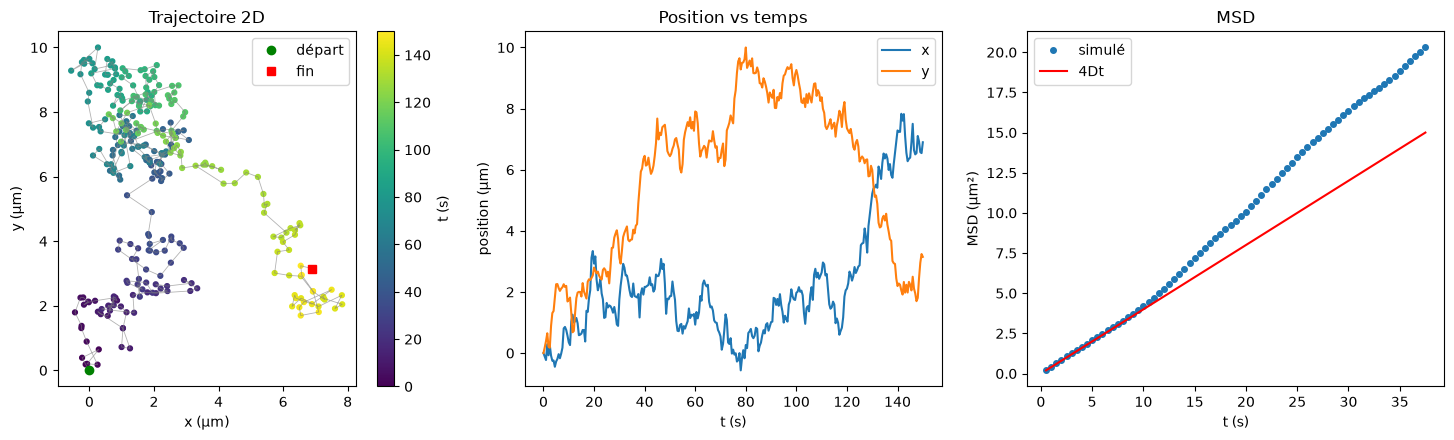

In [113]:
def coeff_diffusion(a, T=T, eta=ETA):
    """Stokes-Einstein (Éq. 5): a en m -> D en m²/s."""
    return kB * T / (6 * np.pi * eta * a)

def brownien(D, dt, n_pas, n_dim=2, rng=np.random.default_rng()):
    """Trajectoire brownienne partant de l'origine. Retourne t (s) et positions (m)."""
    dpos = rng.normal(0, np.sqrt(2 * D * dt), size=(n_pas, n_dim))
    pos = np.vstack([np.zeros(n_dim), np.cumsum(dpos, axis=0)])   # inclut t = 0
    t = np.arange(n_pas + 1) * dt
    return t, pos

def msd_temporel(pos, lag_max):
    """MSD moyenné dans le temps pour les lags 1..lag_max (ignore les images manquantes, NaN)."""
    lags = np.arange(1, lag_max + 1)
    msd = np.array([np.nanmean(np.sum((pos[k:] - pos[:-k])**2, axis=1)) for k in lags])
    return lags, msd

# SIMULATION ET AFFICHAGE
t, pos = brownien(D_REF, PAS_TEMPS, N_PAS, rng=rng)
pos_um = pos * 1e6 # conversion en micromètres

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))

# 1) trajectoire colorée par le temps
ax[0].plot(pos_um[:, 0], pos_um[:, 1], color="gray", lw=0.6, alpha=0.6)
sc = ax[0].scatter(pos_um[:, 0], pos_um[:, 1], c=t, cmap="viridis", s=12)
ax[0].plot(*pos_um[0], "go", label="départ")
ax[0].plot(*pos_um[-1], "rs", label="fin")
ax[0].set_aspect("equal")
ax[0].set(xlabel="x (µm)", ylabel="y (µm)", title="Trajectoire 2D")
ax[0].legend()
fig.colorbar(sc, ax=ax[0], label="t (s)")

# 2) x(t) et y(t)
ax[1].plot(t, pos_um[:, 0], label="x")
ax[1].plot(t, pos_um[:, 1], label="y")
ax[1].set(xlabel="t (s)", ylabel="position (µm)", title="Position vs temps")
ax[1].legend()

# 3) MSD simulé vs théorie (Éq. 6 avec N = 2)
lags, msd = msd_temporel(pos, lag_max=N_PAS // 4)
ax[2].plot(lags * PAS_TEMPS, msd * 1e12, "o", ms=4, label="simulé")
ax[2].plot(lags * PAS_TEMPS, 4 * D_REF * lags * PAS_TEMPS * 1e12, "r-", label="4Dt")
ax[2].set(xlabel="t (s)", ylabel="MSD (µm²)", title="MSD")
ax[2].legend()

plt.tight_layout()
plt.show()


### Simulation avec PSF et bruit de fond 

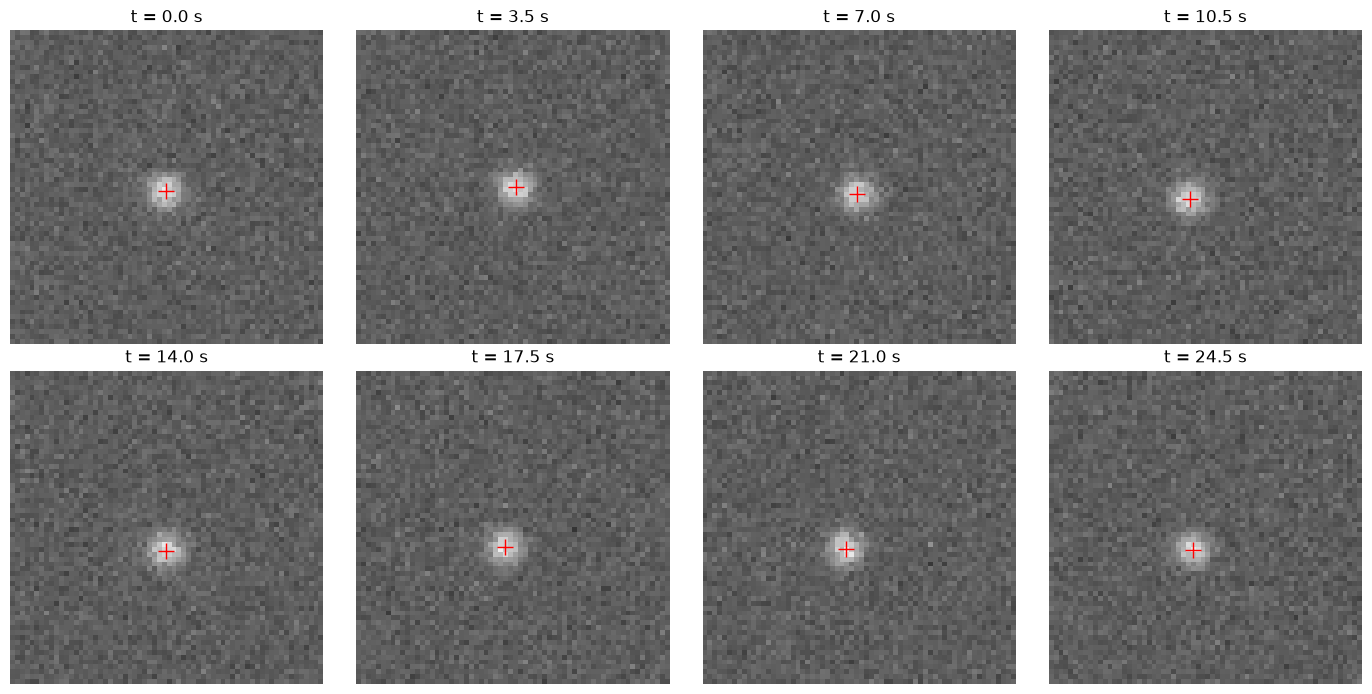

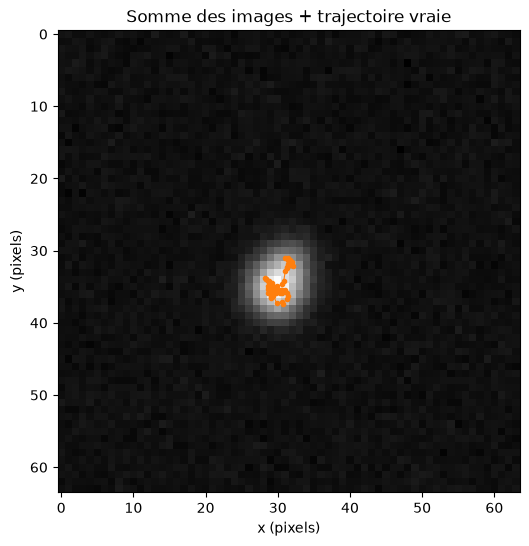

In [114]:
def simuler_video(D, n_images=50, taille=64, n_photons=5000, sigma_psf=SIGMA_PSF_PX,
                  tau=DUREE_EXPOSITION, dt=PAS_TEMPS, n_sous=10,
                  fond=FOND, bruit_lecture=BRUIT_LECTURE, n_bits=N_BITS, rng=rng):
    """
    Simule une vidéo d'une particule brownienne avec PSF gaussienne.
    Retourne: video (n_images, taille, taille), vrai (n_images, 2) en pixels (x, y),
    traj (positions fines en pixels).
    """
    assert tau <= dt, "Le temps d'exposition doit être <= à l'intervalle entre images"
    dt_fin = tau / n_sous                 # pas de temps fin pour le flou de mouvement
    k = int(round(dt / dt_fin))           # nb de pas fins par image (>= n_sous)

    # trajectoire fine, départ près du centre avec un décalage sous-pixel aléatoire
    _, pos = brownien(D, dt_fin, n_images * k, rng=rng)
    traj = pos / PIXEL_EFF + taille / 2 + rng.uniform(-0.5, 0.5, size=2)

    g = np.arange(taille)
    s = sigma_psf * np.sqrt(2)
    video = np.zeros((n_images, taille, taille))
    vrai = np.zeros((n_images, 2))

    for i in range(n_images):
        sous = traj[i * k : i * k + n_sous]        # positions pendant l'exposition
        vrai[i] = sous.mean(axis=0)                # position "vraie" moyenne sur l'exposition
        # intégrale de la gaussienne sur chaque pixel (plus exact que d'évaluer au centre)
        px = 0.5 * (erf((g + 0.5 - sous[:, [0]]) / s) - erf((g - 0.5 - sous[:, [0]]) / s))
        py = 0.5 * (erf((g + 0.5 - sous[:, [1]]) / s) - erf((g - 0.5 - sous[:, [1]]) / s))
        img = (n_photons / n_sous) * np.einsum('sy,sx->yx', py, px)

        # bruit: Poisson (photons + fond) + lecture, puis quantification et saturation
        img = rng.poisson(img + fond) + rng.normal(0, bruit_lecture, img.shape)
        video[i] = np.clip(np.round(img), 0, 2**n_bits - 1)

    return video, vrai, traj

# --- Simulation ---
video, vrai, traj = simuler_video(D_REF, n_images=N_IM, n_photons=5000, rng=rng)

# --- Visualisation: 8 images avec la position vraie ---
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, i in zip(axes.ravel(), np.linspace(0, N_IM - 1, 8).astype(int)):
    ax.imshow(video[i], cmap="gray", vmin=0, vmax=video.max())
    ax.plot(*vrai[i], "r+", ms=12)
    ax.set_title(f"t = {i * PAS_TEMPS:.1f} s")
    ax.axis("off")
plt.tight_layout()
plt.show()

# --- Trajectoire superposée à la somme des images ---
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(video.sum(axis=0), cmap="gray")
ax.plot(vrai[:, 0], vrai[:, 1], "-o", color="tab:orange", ms=3, lw=0.8)
ax.set(title="Somme des images + trajectoire vraie", xlabel="x (pixels)", ylabel="y (pixels)")
plt.show()

### Techniques de localisation de la particule

1. Détection du maximum pur et dur
2. Position des pixels pondérée par leur intensité (slide 40)
2. Fit gaussien en 2D --> maximum 
    2.1. enregistrer en mémoire aussi la largeur à mi-hauteur (LMH) + incertitude, ce qui permettra de comparer pourquoi c'est nécessaire de tracker la particule en plus de l'imager.

méthode             erreur x,y (px)       σ_loc x,y (px)   σ_loc (nm)
Max brut         -0.202,  +0.032      0.537,   0.643          295
Centroïde        -0.072,  +0.022      0.172,   0.179           88
Fit gaussien     -0.004,  -0.013      0.082,   0.066           37


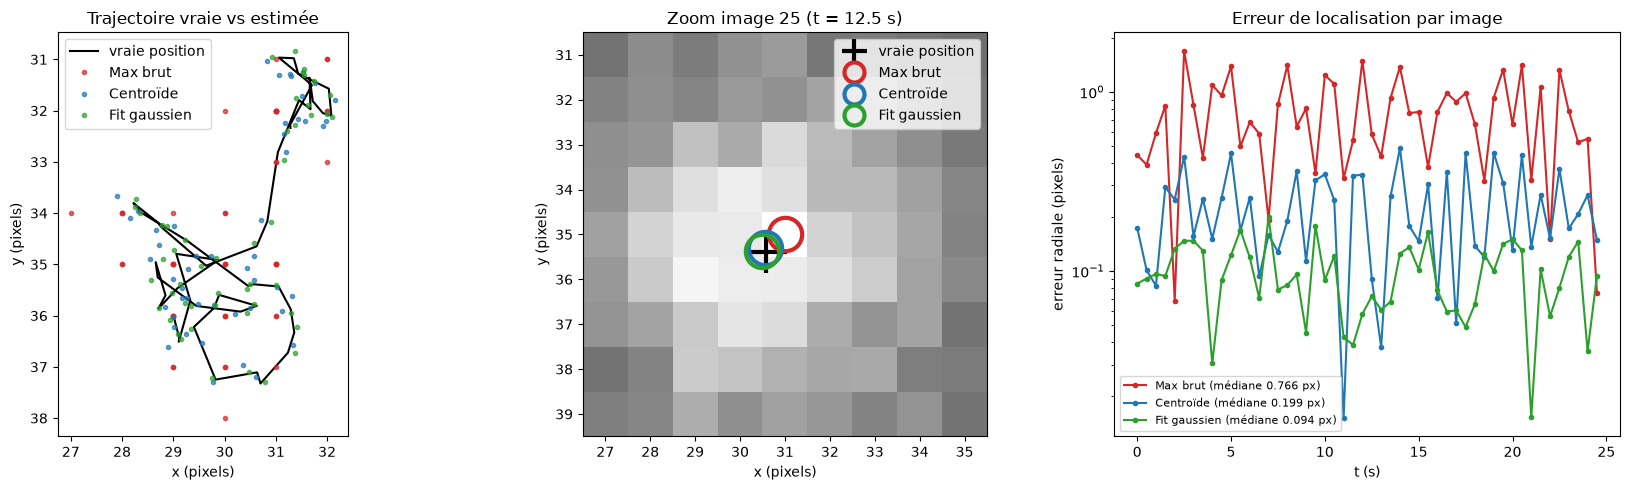

In [115]:


def detect_max(img):
    """Pixel le plus intense. Incertitude = 1/sqrt(12) px (discrétisation seulement)."""
    iy, ix = np.unravel_index(np.argmax(img), img.shape)
    inc = 1 / np.sqrt(12) # car ecart-type de loi uniforme entre -0,5 et 0,5 pixel
    return (float(ix), float(iy)), (inc, inc)

# fonctions additionnelles pour centrer la PSF dans une image
def demi_region_auto(sigma_psf=None):
    """Demi-largeur de la région d'intérêt = 3 sigma (en pixels, arrondi vers le haut)."""
    # 3 sigma permet de couvrir 99% de l'énergie de la gaussienne
    if sigma_psf is None:
        sigma_psf = SIGMA_PSF_PX
    return int(np.ceil(3 * sigma_psf))

def region_interet(img, cx, cy, demi_region):
    """Fenêtre carrée autour de (cx, cy), coupée aux bords. Retourne sous-image, X, Y."""
    x0, x1 = max(int(round(cx)) - demi_region, 0), min(int(round(cx)) + demi_region + 1, img.shape[1])
    y0, y1 = max(int(round(cy)) - demi_region, 0), min(int(round(cy)) + demi_region + 1, img.shape[0])
    Y, X = np.mgrid[y0:y1, x0:x1]
    return img[y0:y1, x0:x1].astype(float), X, Y


def detect_max_pondere(img, sigma_psf=None, demi_region=None, bruit_lecture=BRUIT_LECTURE):
    """Centroïde pondéré (fond soustrait) dans la région d'intérêt.
    Si demi_region est None, il est fixé à 3 sigma_psf."""
    if demi_region is None:
        demi_region = demi_region_auto(sigma_psf)
    (mx, my), _ = detect_max(img)
    fond = np.median(img)
    sub, X, Y = region_interet(img, mx, my, demi_region)
    w = np.clip(sub - fond, 0, None)
    S = w.sum()
    if S <= 0:
        return (np.nan, np.nan), (np.nan, np.nan)
    xc, yc = (w * X).sum() / S, (w * Y).sum() / S
    var_i = np.clip(sub, 0, None) + bruit_lecture**2
    sx = np.sqrt((var_i * (X - xc)**2).sum()) / S
    sy = np.sqrt((var_i * (Y - yc)**2).sum()) / S
    return (xc, yc), (sx, sy)

def _gauss2d(coords, A, x0, y0, sigma, b):
    X, Y = coords
    return (A * np.exp(-((X - x0)**2 + (Y - y0)**2) / (2 * sigma**2)) + b).ravel()

def detect_max_gauss(img, sigma_psf=None, demi_region=None, bruit_lecture=BRUIT_LECTURE, retour_lmh=False):
    """Fit gaussien 2D isotrope (A, x0, y0, sigma, fond), moindres carrés pondérés.
    Si demi_region est None, il est fixé à 3 sigma_psf.
    Si retour_lmh=True, retourne aussi (LMH, incertitude LMH) en pixels. 
    C'est pour pouvoir comparer avec la méthode du tracking et de la diffusivité pour trouver a!"""
    if sigma_psf is None:
        sigma_psf = SIGMA_PSF_PX
    if demi_region is None:
        demi_region = demi_region_auto(sigma_psf)
    (mx, my), _ = detect_max(img)
    sub, X, Y = region_interet(img, mx, my, demi_region)
    b0 = np.median(img)
    p0 = [sub.max() - b0, mx, my, sigma_psf, b0]
    bornes = ([0, X.min(), Y.min(), 0.3, 0], [np.inf, X.max(), Y.max(), 4 * demi_region, np.inf])
    sig = np.sqrt(np.clip(sub, 1, None) + bruit_lecture**2).ravel()
    try:
        p, cov = curve_fit(_gauss2d, (X, Y), sub.ravel(), p0=p0, sigma=sig,
                           absolute_sigma=True, bounds=bornes)
        err = np.sqrt(np.diag(cov))
    except (RuntimeError, ValueError):
        p, err = np.full(5, np.nan), np.full(5, np.nan)
    pos, inc = (p[1], p[2]), (err[1], err[2])
    if retour_lmh:
        k = 2 * np.sqrt(2 * np.log(2))          # LMH = 2,355 sigma
        return pos, inc, (k * p[3], k * err[3])
    return pos, inc


"""Exemple d'application"""
methodes = {"Max brut": detect_max, "Centroïde": detect_max_pondere, "Fit gaussien": detect_max_gauss}
couleurs = {"Max brut": "tab:red", "Centroïde": "tab:blue", "Fit gaussien": "tab:green"}

# positions estimées par chaque méthode (n_images, 2) en pixels
est = {nom: np.array([f(im)[0] for im in video]) for nom, f in methodes.items()}
erreur = {nom: est[nom] - vrai for nom in methodes}
err_rad = {nom: np.hypot(*erreur[nom].T) for nom in methodes}      # erreur radiale (px)
t = np.arange(N_IM) * PAS_TEMPS

# --- tableau de résultats ---
print(f"{'méthode':14s} {'erreur x,y (px)':>20s} {'σ_loc x,y (px)':>20s} {'σ_loc (nm)':>12s}")
for nom in methodes:
    e = erreur[nom]
    sl = np.nanstd(e, axis=0)
    print(f"{nom:14s} {np.nanmean(e[:,0]):+8.3f},{np.nanmean(e[:,1]):+8.3f} {sl[0]:10.3f},{sl[1]:8.3f} {np.mean(sl)*PIXEL_EFF*1e9:12.0f}")

# --- figure ---
i0 = N_IM // 2   # image affichée en zoom
fig, ax = plt.subplots(1, 3, figsize=(17, 5))

# (a) trajectoires
ax[0].plot(vrai[:, 0], vrai[:, 1], "k-", lw=1.5, label="vraie position")
for nom in methodes:
    ax[0].plot(est[nom][:, 0], est[nom][:, 1], ".", color=couleurs[nom], ms=6, alpha=0.7, label=nom)
ax[0].set_aspect("equal"); ax[0].invert_yaxis()
ax[0].set(xlabel="x (pixels)", ylabel="y (pixels)", title="Trajectoire vraie vs estimée")
ax[0].legend()

# (b) zoom sur une image
demi_zoom = demi_region_auto() // 2   # moitié de la demi-largeur actuelle (8 → 4, soit 9×9 pixels)
cx, cy = vrai[i0]
x0, y0 = int(round(cx)) - demi_zoom, int(round(cy)) - demi_zoom
ax[1].imshow(video[i0], cmap="gray", vmin=0, vmax=video[i0].max())
ax[1].plot(*vrai[i0], "k+", ms=30, mew=3, label="vraie position")
for nom in methodes:
    ax[1].plot(*est[nom][i0], "o", mfc="none", mec=couleurs[nom], ms=24, mew=3, label=nom)
ax[1].set_xlim(x0 - 0.5, x0 + 2*demi_zoom + 0.5)
ax[1].set_ylim(y0 + 2*demi_zoom + 0.5, y0 - 0.5)
ax[1].set(xlabel="x (pixels)", ylabel="y (pixels)", title=f"Zoom image {i0} (t = {t[i0]:.1f} s)")
ax[1].legend(loc="upper right", fontsize=10, markerscale=0.6)

# (c) erreur radiale vs temps
for nom in methodes:
    ax[2].plot(t, err_rad[nom], "-o", ms=3, color=couleurs[nom],
               label=f"{nom} (médiane {np.nanmedian(err_rad[nom]):.3f} px)")
ax[2].set_yscale("log")
ax[2].set(xlabel="t (s)", ylabel="erreur radiale (pixels)", title="Erreur de localisation par image")
ax[2].legend(fontsize=8)

plt.tight_layout()
plt.show()


On voit clairement que la meilleure méthode de détection est le fit gaussien, démontrant à la fois la plus petite erreur sur la position et la plus petite incertitude.

### Calcul du rayon et de son incertitude

Rayon réel   : 2.274 µm
Rayon mesuré : 2.165 ± 0.670 µm (stat)
Erreur       : -0.109 µm  (-4.8 %,  -0.16 σ stat)


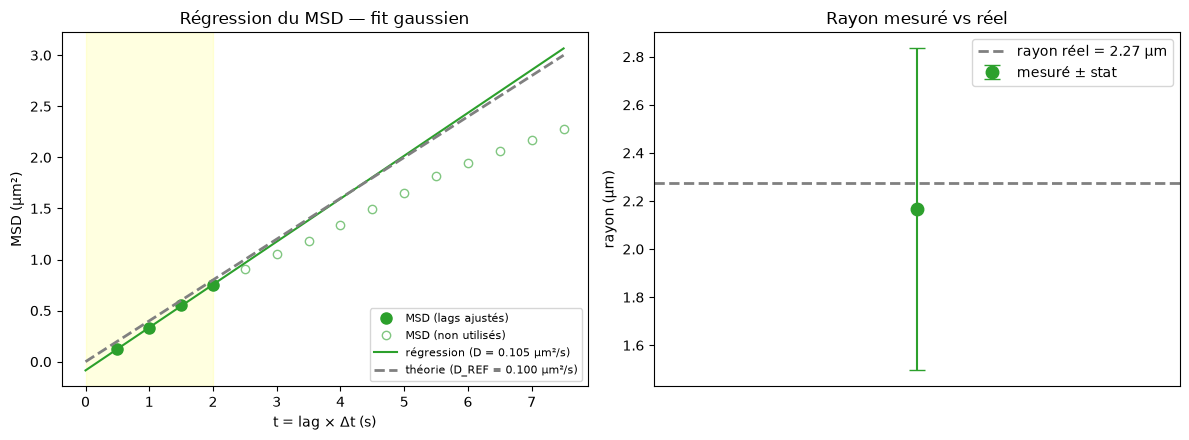

In [116]:


def _ajuste_msd(pos, dt, lag_max):
    """Ajuste MSD = 2N D t + 2N sigma_exp² (Éq. 7). Retourne D (m²/s) et l'offset (m²)."""
    lags, msd = msd_temporel(pos, lag_max)
    pente, offset = np.polyfit(lags * dt, msd, 1)
    return pente / (2 * pos.shape[1]), offset

def calcul_rayon(positions_px, dt=PAS_TEMPS, pixel_eff=PIXEL_EFF, T=T, eta=ETA, lag_max=4,
                 inc_T=1.0, inc_eta_rel=0.03, inc_pixel_rel=0.02,
                 n_boot=200, rng=rng, details=False):
    """
    positions_px : (n_images, 2) positions estimées en pixels (NaN permis pour une image ratée).
    Retourne le rayon a (m) et son incertitude totale (m) = stat ⊕ syst (en quadrature).
    """
    pos = np.asarray(positions_px, float) * pixel_eff
    n_pos, n_dim = pos.shape

    # 1) D par régression du MSD, puis rayon par Stokes-Einstein (Éq. 5)
    D, offset = _ajuste_msd(pos, dt, lag_max)
    if not np.isfinite(D) or D <= 0:
        return (np.nan, np.nan, {}) if details else (np.nan, np.nan)
    a = kB * T / (6 * np.pi * eta * D)

    # 2) incertitude statistique: bootstrap paramétrique
    #    on simule des trajectoires avec le D et le sigma_exp trouvés, on refait le même ajustement
    sigma_exp = np.sqrt(max(offset, 0) / (2 * n_dim))
    D_boot = []
    for _ in range(n_boot):
        sim = np.vstack([np.zeros(n_dim),
                         np.cumsum(rng.normal(0, np.sqrt(2 * D * dt), (n_pos - 1, n_dim)), axis=0)])
        sim += rng.normal(0, sigma_exp, sim.shape)
        D_boot.append(_ajuste_msd(sim, dt, lag_max)[0])
    inc_D = np.std(D_boot)
    inc_stat = a * inc_D / D                      # δa/a = δD/D

    # 3) incertitude systématique: T, η, taille de pixel (D ∝ pixel², donc a ∝ 1/pixel²)
    inc_sys = a * np.sqrt((inc_T / T)**2 + inc_eta_rel**2 + (2 * inc_pixel_rel)**2)

    # 4) somme en quadrature
    inc = np.hypot(inc_stat, inc_sys)
    if details:
        return a, inc, dict(D=D, inc_D=inc_D, sigma_exp=sigma_exp, inc_stat=inc_stat, inc_sys=inc_sys)
    return a, inc


"""Exemple d'application"""
est_gauss = est["Fit gaussien"]
LAG_MAX = 4
a_reel = kB * T / (6 * np.pi * ETA * D_REF)          # rayon vrai (m), d'après D_REF

# --- calcul et erreur ---
a, inc, d = calcul_rayon(est_gauss, lag_max=LAG_MAX, details=True)
err = a - a_reel
print(f"Rayon réel   : {a_reel*1e6:.3f} µm")
print(f"Rayon mesuré : {a*1e6:.3f} ± {d['inc_stat']*1e6:.3f} µm (stat)")
print(f"Erreur       : {err*1e6:+.3f} µm  ({100*err/a_reel:+.1f} %,  {err/d['inc_stat']:+.2f} σ stat)")

# --- courbe de régression ---
lag_aff = 15                                           # lags affichés (au-delà de ceux ajustés)
lags, msd = msd_temporel(est_gauss * PIXEL_EFF, lag_aff)
t = lags * PAS_TEMPS
pente, offset = np.polyfit(t[:LAG_MAX], msd[:LAG_MAX], 1)
t_fit = np.linspace(0, lag_aff * PAS_TEMPS, 100)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(t[:LAG_MAX], msd[:LAG_MAX] * 1e12, "o", color="tab:green", ms=8, label="MSD (lags ajustés)")
ax[0].plot(t[LAG_MAX:], msd[LAG_MAX:] * 1e12, "o", mfc="none", color="tab:green", ms=6, alpha=0.6, label="MSD (non utilisés)")
ax[0].plot(t_fit, (pente * t_fit + offset) * 1e12, "-", color="tab:green", label=f"régression (D = {d['D']*1e12:.3f} µm²/s)")
ax[0].plot(t_fit, 4 * D_REF * t_fit * 1e12, "--", color="gray", lw=2, label=f"théorie (D_REF = {D_REF*1e12:.3f} µm²/s)")
ax[0].axvspan(0, LAG_MAX * PAS_TEMPS, color="yellow", alpha=0.12)
ax[0].set(xlabel="t = lag × Δt (s)", ylabel="MSD (µm²)", title="Régression du MSD — fit gaussien")
ax[0].legend(fontsize=8)

ax[1].errorbar([0], [a * 1e6], yerr=[d["inc_stat"] * 1e6], fmt="o", color="tab:green", capsize=6, ms=9, label="mesuré ± stat")
ax[1].axhline(a_reel * 1e6, color="gray", ls="--", lw=2, label=f"rayon réel = {a_reel*1e6:.2f} µm")
ax[1].set_xticks([])
ax[1].set(ylabel="rayon (µm)", title="Rayon mesuré vs réel")
ax[1].legend()
plt.tight_layout()
plt.show()

Ici, on arrête la régression à lag = 4 (on utilise seulement 4 images avant et apres chaque point) parce que les points aux grands lags sont corrélés entre eux et donc la régression qui les assume indépendants ne fonctionne plus.

### $\sigma_{loc}$ vs nombre de photons (SNR) -- balayage 
Note: cette cellule prend environ 4-5min à rouler (enlever les premiers termes dans NOMBRE_PHOTOS pour réduire le temps)

[1/7] 500 photons (SNR = 1.2)


      terminé en 158 s | σ_loc = 0.755 px | échecs = 84 % | écoulé 158 s, reste ~947 s      
[2/7] 1000 photons (SNR = 2.2)
      terminé en 54 s | σ_loc = 0.352 px | échecs = 29 % | écoulé 212 s, reste ~529 s      
[3/7] 2000 photons (SNR = 4.1)
      terminé en 8 s | σ_loc = 0.181 px | échecs = 0 % | écoulé 219 s, reste ~292 s      
[4/7] 5000 photons (SNR = 8.5)
      terminé en 6 s | σ_loc = 0.081 px | échecs = 0 % | écoulé 226 s, reste ~169 s      
[5/7] 10000 photons (SNR = 13.8)
      terminé en 6 s | σ_loc = 0.045 px | échecs = 0 % | écoulé 232 s, reste ~93 s      
[6/7] 30000 photons (SNR = 26.9)
      terminé en 6 s | σ_loc = 0.020 px | échecs = 0 % | écoulé 237 s, reste ~40 s      
[7/7] 100000 photons (SNR = 51.5)
      terminé en 6 s | σ_loc = 0.009 px | échecs = 0 % | écoulé 243 s, reste ~0 s      
Balayage terminé en 243 s


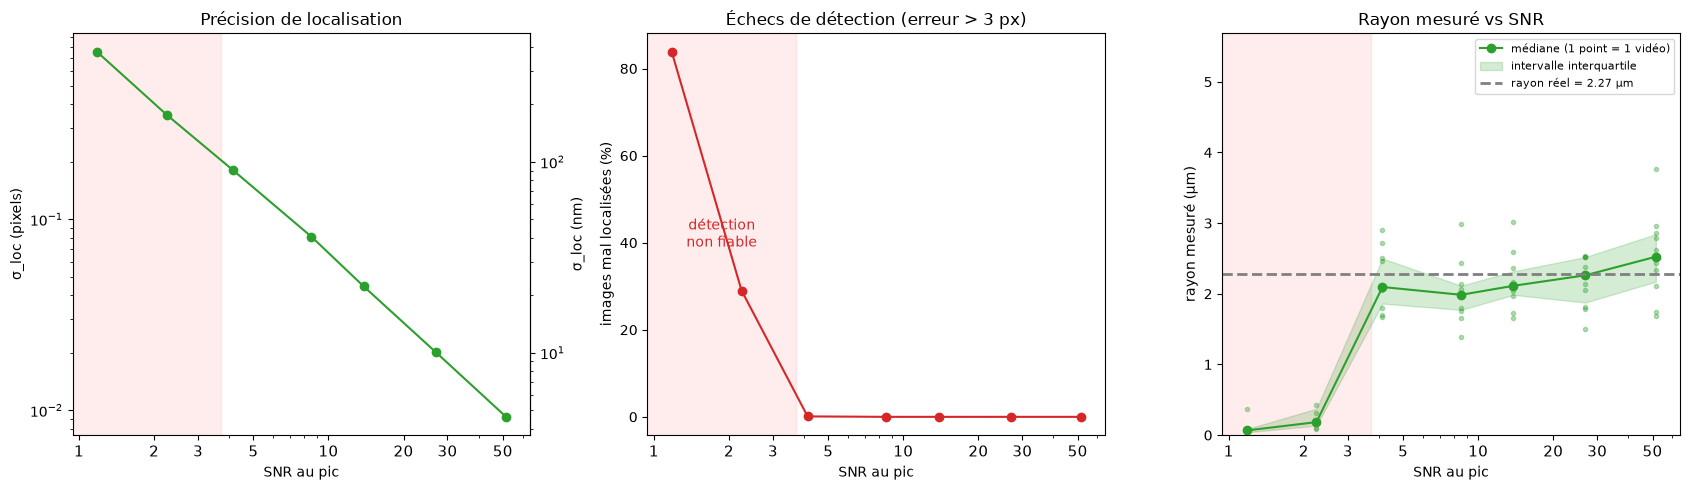

In [ ]:
def snr_pic(n_photons, sigma_psf=SIGMA_PSF_PX, fond=FOND, bruit_lecture=BRUIT_LECTURE):
    """SNR au pic de la PSF: amplitude / écart-type du bruit (Poisson du signal + fond, lecture)."""
    A = n_photons / (2 * np.pi * sigma_psf**2)
    return A / np.sqrt(A + fond + bruit_lecture**2)

def balayage_snr(n_photons_liste, n_videos=20, n_images=100, D=D_REF, taille=64,
                 lag_max=4, seuil_echec_px=3.0, rng=rng):
    """
    Pour chaque nombre de photons: simule n_videos vidéos, localise par fit gaussien et mesure
      - sigma_loc : écart-type de (estimé - vrai) sur les localisations réussies (erreur radiale < seuil)
      - frac_echec : fraction d'images où l'erreur radiale dépasse seuil_echec_px
      - le rayon a de chaque vidéo (aucun filtrage: les échecs contaminent le résultat, comme en vrai)
    """
    out = {k: [] for k in ["n_photons", "snr", "sigma_loc_px", "frac_echec", "a_vals", "inc_stat_med"]}
    n_niv = len(n_photons_liste)
    t_debut = time.time()
    for j, n_ph in enumerate(n_photons_liste, start=1):
        t_niv = time.time()
        print(f"[{j}/{n_niv}] {n_ph} photons (SNR = {snr_pic(n_ph):.1f})")
        erreurs, a_vals, incs = [], [], []
        for v in range(1, n_videos + 1):
            video, vrai, _ = simuler_video(D, n_images=n_images, taille=taille, n_photons=n_ph, rng=rng)
            est = np.array([detect_max_gauss(im)[0] for im in video])
            erreurs.append(est - vrai)
            a, inc, d = calcul_rayon(est, lag_max=lag_max, n_boot=50, rng=rng, details=True)
            if np.isfinite(a):
                a_vals.append(a); incs.append(d["inc_stat"])
            print(f"      vidéo {v}/{n_videos}  ({time.time() - t_niv:.0f} s)", end="\r", flush=True)
        e = np.vstack(erreurs)                                   # (n_videos*n_images, 2)
        rad = np.hypot(e[:, 0], e[:, 1])
        ok = np.isfinite(rad) & (rad < seuil_echec_px)
        out["n_photons"].append(n_ph)
        out["snr"].append(snr_pic(n_ph))
        out["sigma_loc_px"].append(np.sqrt(0.5 * (np.var(e[ok, 0]) + np.var(e[ok, 1]))) if ok.sum() > 10 else np.nan)
        out["frac_echec"].append(1 - ok.mean())
        out["a_vals"].append(np.array(a_vals))
        out["inc_stat_med"].append(np.median(incs) if incs else np.nan)
        ecoule = time.time() - t_debut
        restant = ecoule / j * (n_niv - j)
        print(f"      terminé en {time.time() - t_niv:.0f} s | σ_loc = {out['sigma_loc_px'][-1]:.3f} px | "
              f"échecs = {100 * out['frac_echec'][-1]:.0f} % | écoulé {ecoule:.0f} s, reste ~{restant:.0f} s      ")
    for k in ["n_photons", "snr", "sigma_loc_px", "frac_echec", "inc_stat_med"]:
        out[k] = np.array(out[k])
    print(f"Balayage terminé en {time.time() - t_debut:.0f} s")
    return out

# --- exécution ---
res = balayage_snr(NOMBRE_PHOTONS, n_videos=10, n_images=100)


# GRAPHIQUE 

a_reel = kB * T / (6 * np.pi * ETA * D_REF)
snr = res["snr"]
echec = res["frac_echec"] > 0.05                      # niveaux où plus de 5 % des images sont mal localisées

fig, ax = plt.subplots(1, 3, figsize=(17, 5))

# (a) précision de localisation
ax[0].log(snr, res["sigma_loc_px"], "o-", color="tab:green")
ax[0].set(xlabel="SNR au pic", ylabel="σ_loc (pixels)", title="Précision de localisation")
sec = ax[0].secondary_yaxis("right", functions=(lambda y: y * PIXEL_EFF * 1e9, lambda y: y / (PIXEL_EFF * 1e9)))
sec.set_ylabel("σ_loc (nm)")

# (b) taux d'échec
ax[1].semilogx(snr, 100 * res["frac_echec"], "o-", color="tab:red")
ax[1].set(xlabel="SNR au pic", ylabel="images mal localisées (%)", title="Échecs de détection (erreur > 3 px)")

# (c) rayon mesuré
for i, av in enumerate(res["a_vals"]):
    ax[2].semilogx(np.full(len(av), snr[i]), av * 1e6, ".", color="tab:green", alpha=0.35)
med = np.array([np.median(av) for av in res["a_vals"]]) * 1e6
q25 = np.array([np.percentile(av, 25) for av in res["a_vals"]]) * 1e6
q75 = np.array([np.percentile(av, 75) for av in res["a_vals"]]) * 1e6
ax[2].plot(snr, med, "o-", color="tab:green", label="médiane (1 point = 1 vidéo)")
ax[2].fill_between(snr, q25, q75, color="tab:green", alpha=0.2, label="intervalle interquartile")
ax[2].axhline(a_reel * 1e6, color="gray", ls="--", lw=2, label=f"rayon réel = {a_reel*1e6:.2f} µm")
ax[2].set(xlabel="SNR au pic", ylabel="rayon mesuré (µm)", title="Rayon mesuré vs SNR", ylim=(0, 2.5 * a_reel * 1e6))
ax[2].legend(fontsize=8)

# axe des x: nombres lisibles (au lieu de 10⁰, 10¹ seulement)
ticks = [t for t in [1, 2, 3, 5, 10, 20, 30, 50, 100] if snr.min() * 0.8 <= t <= snr.max() * 1.25]
for a in ax:
    a.set_xticks(ticks)
    a.xaxis.set_major_formatter(ScalarFormatter())
    a.xaxis.set_minor_formatter(NullFormatter())
    a.set_xlim(snr.min() * 0.8, snr.max() * 1.25)
    a.tick_params(axis="x", labelsize=11)

# zone rouge: niveaux de SNR où la détection échoue (résultats non fiables)
if echec.any():
    x_fin = snr[~echec].min() * 0.9
    for a in ax:
        a.axvspan(snr.min() * 0.8, x_fin, color="red", alpha=0.07)
    ax[1].text(np.sqrt(snr.min() * 0.8 * x_fin), 0.5, "détection\nnon fiable", color="tab:red", ha="center",
               va="center", transform=ax[1].get_xaxis_transform(), fontsize=10)

plt.tight_layout()
plt.show()

On en déduit qu'à partir de 2000 photons (SNR de 2.2), la localisation devient fiable et on obtient une bonne estimation de rayon. De plus, agrandir le SNR réduit l'incertitude sur la localisation de façon exponentielle.

### $\sigma_{loc}$ vs durée de l'exposition (sous-échantillonnage) -- balayage

Influence du grossissement: LMH par rapport à champ de vision. déduire champ de vision: calculs optique

secondaire ### $\sigma_{loc}$ vs taille -- balayage 

secondaire ### $\sigma_{a}$ selon # images acquises -- balayage

# Partie 2 - Analyse des vidéos de référence

### Ouverture et analyse des fichiers .tif

### Acquisition monochromatique en noir/blanc vs RGB

### Acquisition 8 bit vs 16 bits

### Techniques de réduction du bruit* --> contraste 
*peut-être moins pertinent pour ce rapport, faire à la fin

1. Aucune réduction
2. Moyenne sur zone faible intensité et on enlève partout 
3. Filtre gaussien ou soustraction de fond glissante (attention idée de claude ici)

# Partie 3 - Analyse, beaux graphiques